# SEM receivers · pressure, particle velocity, rotation and DAS strain

One simulation, the sensors of a marine survey: a dual-sensor streamer in the water (pressure
and vertical particle velocity), nodes on the sea floor (velocity, pressure, rotation) and a DAS
fibre laid along it (strain rate). The SEM records each of them where it sits: a receiver takes
the field -- or, for the strain, the rotation, the pressure in the rock and the particle motion
in the water, the gradient of its element's basis -- at its point, the seismograms SPECFEM2D's
`seismotype` 1-5 give.

| `receiver_type` | in the water | in the rock |
|---|---|---|
| `p` | `-d2(chi)/dt2` | `-kappa div u` |
| `vx`, `vz` | `grad(chi_dot) / rho` | `du/dt` |
| `rot_y` | 0 | `curl(u) / 2` |
| `exx_t` | 0 | `d(vx)/dx`, the strain rate along x |

See [Strain, rotation and pressure](../user-guide/sem.md#strain-rotation-and-pressure).

In [1]:
import time

import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import AcousticElasticSEM2D, PropSEM

DEV = "cuda" if torch.cuda.is_available() else "cpu"
DH, NO = 5.0, 4                          # grid cell; elements of 4 cells = 20 m
NX, NZ = 801, 301                        # 4000 m x 1500 m
F0, T_REC = 10.0, 2.0
DT = 4e-4                                # Courant 0.3 on the smallest GLL gap at 2500 m/s
NT = int(round(T_REC / DT))
WATER = dict(vp=1500.0, vs=0.0, rho=1020.0)
ROCK = dict(vp=2500.0, vs=1250.0, rho=2200.0)


def floor(x):
    """Sea-floor depth (m): 300 m, a seamount up to 200 m at x = 2600 m."""
    return 300.0 - 100.0 * np.exp(-((x - 2600.0) / 350.0) ** 2)


print(f"dt = {DT:.1e} s, {NT} steps, device {DEV}")

dt = 4.0e-04 s, 5000 steps, device cuda


## 1. Model and acquisition

`interfaces` gives the sea floor, top-down rows per column, and the Quad9 mesh follows it
(`interface_elements`: element rows per layer). Every receiver below is one row of the same
`receivers` array and records all five components; each group keeps the ones its sensor
measures.

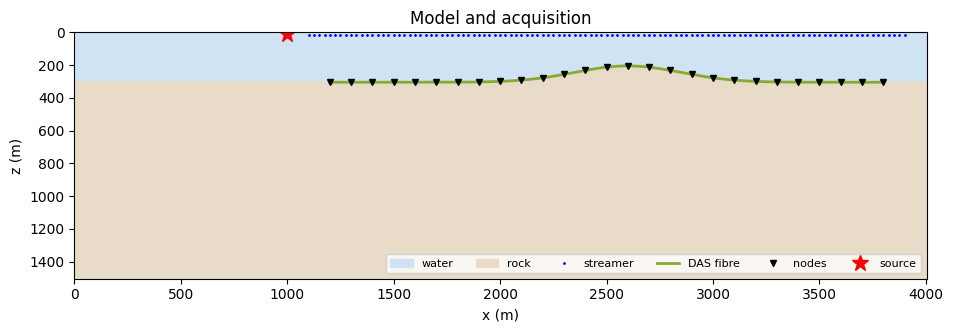

In [2]:
xg = np.arange(NX) * DH
prop = PropSEM(AcousticElasticSEM2D, shape=(NZ, NX), dh=DH, dt=DT, n_order=NO,
               interfaces=[floor(xg) / DH], interface_elements=[15, 60],
               free_surface=True, f_dominant=F0, source_type=["chi"],
               receiver_type=["p", "vx", "vz", "rot_y", "exx_t"],
               impl="eager", dev=DEV, dtype=torch.float32)
models = [prop.layered_model([WATER[k], ROCK[k]]) for k in ("vp", "vs", "rho")]

src = np.array([[200, 2]])                                  # airgun: x 1000 m, 10 m deep
x_str = np.arange(1100.0, 3901.0, 25.0)                     # streamer, 15 m deep
x_obn = np.arange(1200.0, 3801.0, 100.0)                    # nodes, 5 m below the floor
x_das = np.arange(1200.0, 3801.0, 10.0)                     # fibre, 5 m below the floor
x_pair = np.array([1600.0, 2600.0, 3400.0])                 # 5 mm above / below the floor
x_fd = np.array([2999.5, 3000.5])                           # 1 m apart, the depth of the channel
groups = {"streamer": np.stack([x_str, np.full_like(x_str, 15.0)], 1),
          "nodes": np.stack([x_obn, floor(x_obn) + 5.0], 1),
          "fibre": np.stack([x_das, floor(x_das) + 5.0], 1),
          "above": np.stack([x_pair, floor(x_pair) - 0.005], 1),
          "below": np.stack([x_pair, floor(x_pair) + 0.005], 1),
          "fd": np.stack([x_fd, np.full_like(x_fd, floor(3000.0) + 5.0)], 1)}
rec = np.concatenate(list(groups.values())) / DH            # metres -> grid indices
sl, lo = {}, 0
for k, v in groups.items():
    sl[k] = slice(lo, lo + len(v)); lo += len(v)

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.fill_between(xg, 0, floor(xg), color="#cfe3f5", label="water")
ax.fill_between(xg, floor(xg), NZ * DH, color="#e8dcc8", label="rock")
ax.plot(*groups["streamer"].T, "b.", ms=2, label="streamer")
ax.plot(*groups["fibre"].T, "-", color="#8a3", lw=2, label="DAS fibre")
ax.plot(*groups["nodes"].T, "kv", ms=4, label="nodes")
ax.plot(src[0, 0] * DH, src[0, 1] * DH, "r*", ms=12, label="source")
ax.set_ylim(NZ * DH, 0); ax.set_xlim(0, NX * DH)
ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)"); ax.legend(ncol=6, fontsize=8, loc="lower right")
ax.set_title("Model and acquisition"); plt.show()

## 2. One run

The pressure source loads the potential with the wavelet over the water's bulk modulus
(`chi` source, SPECFEM2D's normalisation).

In [3]:
t = np.arange(NT) * DT
a = (np.pi * F0 * (t - 1.2 / F0)) ** 2
wav = torch.tensor((1.0 - 2.0 * a) * np.exp(-a) / (WATER["rho"] * WATER["vp"] ** 2),
                   dtype=torch.float32, device=DEV)
t0 = time.time()
with torch.no_grad():
    seis = prop(wav, src, rec[None], models=models)[0].cpu().numpy()   # (nt, nrec, 5)
print(f"{time.time() - t0:.1f} s, seismograms {seis.shape}")
P, VX, VZ, ROT, EXX_T = range(5)

sweep: torch.compile is compiling the AcousticElasticSEM2D step for a 301x801 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


6.8 s, seismograms (5000, 409, 5)


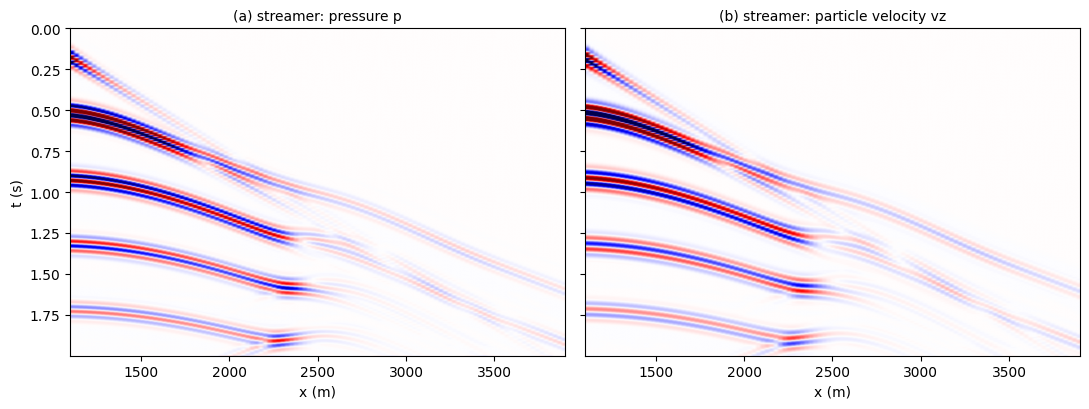

In [4]:
def gather(ax, data, x, title, clip=0.995):
    v = np.quantile(np.abs(data), clip)
    ax.imshow(data, aspect="auto", cmap="seismic", vmin=-v, vmax=v,
              extent=[x[0], x[-1], t[-1], t[0]])
    ax.set_title(title, fontsize=10); ax.set_xlabel("x (m)")


fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
gather(ax[0], seis[:, sl["streamer"], P], x_str, "(a) streamer: pressure p")
gather(ax[1], seis[:, sl["streamer"], VZ], x_str, "(b) streamer: particle velocity vz")
ax[0].set_ylabel("t (s)"); plt.tight_layout(); plt.show()

The streamer's two channels differ where the sea surface reflects: the pressure-free surface
changes the sign of the downgoing pressure but not that of the downgoing particle velocity, which
is what dual-sensor deghosting combines. In the water `vz` is the potential's gradient over the
density.

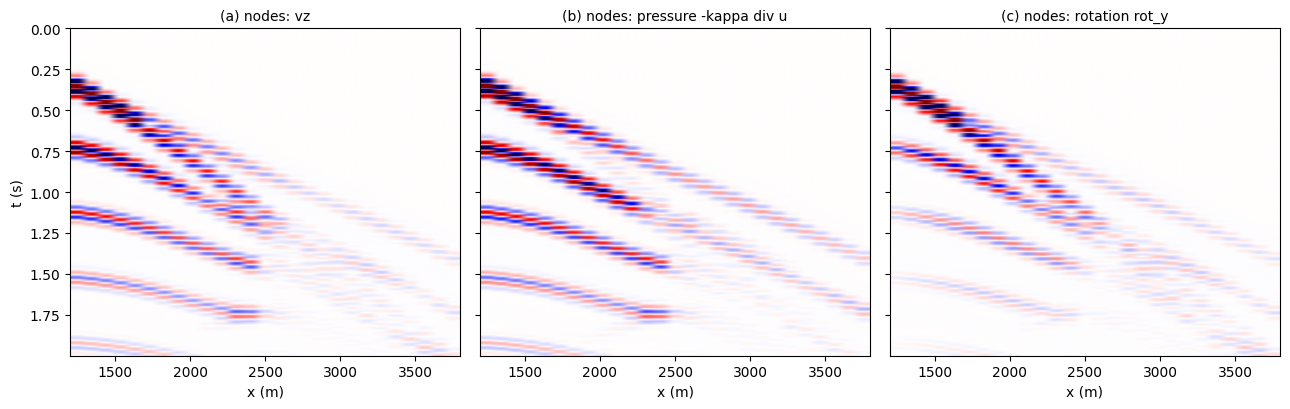

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
gather(ax[0], seis[:, sl["nodes"], VZ], x_obn, "(a) nodes: vz")
gather(ax[1], seis[:, sl["nodes"], P], x_obn, "(b) nodes: pressure -kappa div u")
gather(ax[2], seis[:, sl["nodes"], ROT], x_obn, "(c) nodes: rotation rot_y")
ax[0].set_ylabel("t (s)"); plt.tight_layout(); plt.show()

All three record the arrivals from the water column -- the direct wave and the water-layer
multiples -- as they cross the floor. The pressure takes their P part (`div u`) and the rotation
their S part (`curl u`), so the two weigh the same arrivals differently along the line.

## 3. DAS strain rate and two checks

The fibre records `exx_t = d(vx)/dx`. Two more receivers 1 m apart around x = 3000 m, at that
channel's depth, give the same strain rate as a centred difference of their `vx` (a difference
across the fibre's own 10 m channels errs by several percent on the slow Scholte wave).

exx_t at x = 3000 m against the difference of vx: rel L2 3.4e-04


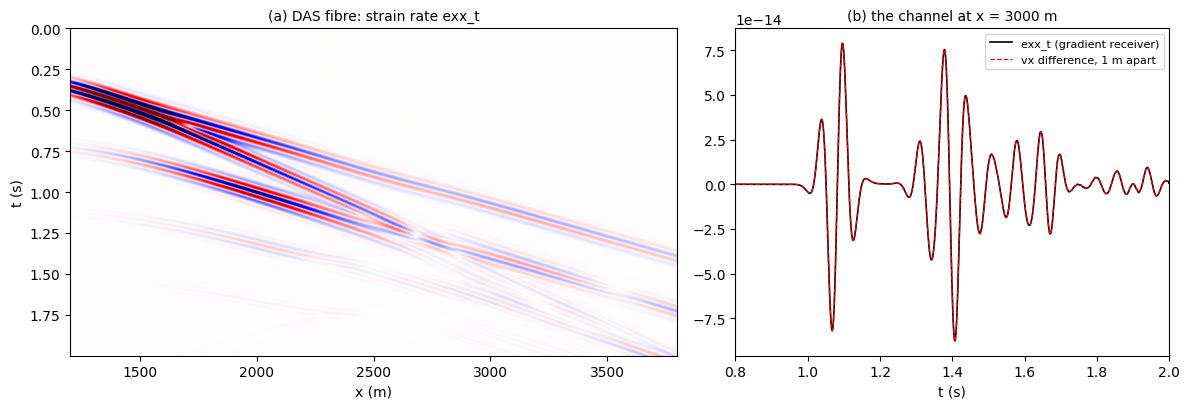

In [6]:
vx_pair = seis[:, sl["fd"], VX]
fd = vx_pair[:, 1] - vx_pair[:, 0]                          # / 1 m
das = seis[:, sl["fibre"], EXX_T][:, np.argmin(np.abs(x_das - 3000.0))]
print(f"exx_t at x = 3000 m against the difference of vx: rel L2 "
      f"{np.linalg.norm(das - fd) / np.linalg.norm(fd):.1e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
gather(ax[0], seis[:, sl["fibre"], EXX_T], x_das, "(a) DAS fibre: strain rate exx_t")
ax[0].set_ylabel("t (s)")
ax[1].plot(t, das, "k", lw=1.2, label="exx_t (gradient receiver)")
ax[1].plot(t, fd, "r--", lw=0.9, label="vx difference, 1 m apart")
ax[1].set_xlim(0.8, T_REC); ax[1].set_xlabel("t (s)")
ax[1].set_title("(b) the channel at x = 3000 m", fontsize=10); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The fluid and the solid meet at the floor, where the coupling keeps the normal particle velocity
continuous -- in the weak form, so up to the discretisation error -- while the tangential one
slips: just above, `vz` is the water's `grad(chi_dot)/rho`, just below the rock's `du/dt`.

In [7]:
for j, x in enumerate(x_pair):
    up, dn = seis[:, sl["above"], :][:, j], seis[:, sl["below"], :][:, j]
    rel = np.linalg.norm(up[:, VZ] - dn[:, VZ]) / np.linalg.norm(dn[:, VZ])
    slip = np.linalg.norm(up[:, VX]) / np.linalg.norm(dn[:, VX])
    print(f"x = {x:.0f} m: vz above vs below rel L2 {rel:.1e}; |vx| above / below {slip:.2f}")

x = 1600 m: vz above vs below rel L2 2.4e-03; |vx| above / below 1.21
x = 2600 m: vz above vs below rel L2 1.5e-03; |vx| above / below 1.03
x = 3400 m: vz above vs below rel L2 1.5e-02; |vx| above / below 0.83


## 4. Notes

- **Where a receiver sits.** On `AcousticElasticSEM2D` each receiver takes its element's medium:
  `vx`, `vz` and `p` are the water's in the water and the rock's in the rock, and the strain and
  rotation are zero in the water.
- **Element edges.** The field's gradient jumps across element edges, so a receiver on one --
  here every other DAS channel -- takes the elements that meet there by their shares, as a moment
  source is spread over them. SPECFEM2D takes one of them; off the edges the two codes agree to
  round-off.
- **Velocity-stress classes.** Their fields are the velocity, so their strain is the running
  sum of the strain rate times `dt`, the displacement their leapfrog integrates.
- **Gradients.** The receivers are linear in the fields and carry their material factor (`rho`,
  `kappa` at the receiver), so `loss.backward()` goes through them on both backends.

---

<p><strong>Download this notebook</strong> &mdash; <a href="47_sem_receivers.ipynb" download><code>47_sem_receivers.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/47_sem_receivers.ipynb">view on GitHub</a></p>